# Home Credit Default Risk — GCI World 2026 September Competition Solution

**Goal:** predict the probability that each applicant defaults (`TARGET = 1`). **Metric:** ROC-AUC.

**Approach summary**

| Step | What I did | Why |
|---|---|---|
| 1. EDA | Checked target imbalance, missing values, anomalies (`DAYS_EMPLOYED = 365243`, `OWN_CAR_AGE ≥ 60`, `XNA` categories) | Decide preprocessing |
| 2. Cleaning | Turned anomalies into `NaN` + kept an indicator flag | Tree models treat NaN natively; the flag preserves the information |
| 3. Feature engineering | ~110 new features: implied interest rate & loan term, model-based EXT_SOURCE imputation, financial ratios (credit/annuity ≈ loan term, annuity/income …), EXT_SOURCE aggregates, time ratios, group-relative features, count encodings | Domain knowledge of credit risk |
| 4. Validation | 5-fold **Stratified K-Fold** CV (instead of a single hold-out) | Reliable estimate under 8% class imbalance |
| 5. Models | LightGBM, CatBoost, XGBoost (gradient-boosted trees, early stopping) | Strong on tabular data; different inductive biases help the ensemble |
| 6. Ensemble | Rank-average blend, weights chosen on out-of-fold (OOF) predictions | AUC only depends on ranking; rank averaging is robust to calibration differences |

**Compliance with the competition rules:** only `input/train.csv` and `input/test.csv` are used (no external data); every prediction comes from the model (no hand-labeling); all random seeds are fixed (`SEED = 42`) for reproducibility. Group statistics and count encodings are computed from feature columns only — the target is never used outside the training folds.

**References / credits:** the feature ideas (credit/annuity ratio, EXT_SOURCE combinations, `DAYS_EMPLOYED` anomaly) are well-known findings from public discussions of the original Kaggle *Home Credit Default Risk* competition (2018), e.g. Will Koehrsen, *"Start Here: A Gentle Introduction"* (Kaggle notebook) and the Kaggle discussion forum. The structure follows the provided `tutorial.ipynb`. All code in this notebook was written for this competition.

## 1. Setup

In [1]:
# !pip install -q lightgbm catboost xgboost   # uncomment if a library is missing (Colab has lightgbm & xgboost; catboost may need installing)
import os, random, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
N_FOLDS = 5
N_JOBS = os.cpu_count()
print("lightgbm", lgb.__version__, "| xgboost", xgb.__version__, "| pandas", pd.__version__)

lightgbm 4.7.0 | xgboost 3.4.1 | pandas 2.1.3


In [2]:
# Google Colab: mount Drive and move to the competition folder (skipped automatically when running locally)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    %cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"
except ImportError:
    pass

In [3]:
current_dir = Path(os.getcwd())
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"
assert train_file.exists() and test_file.exists() and sample_sub_file.exists(), "Path is not set correctly"
print("All files exist and path is correctly set.")

All files exist and path is correctly set.


## 2. Loading the Data

In [4]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
print("train", train.shape, "| test", test.shape)
train.head(3)

train (171202, 34) | test (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


## 3. Exploratory Data Analysis

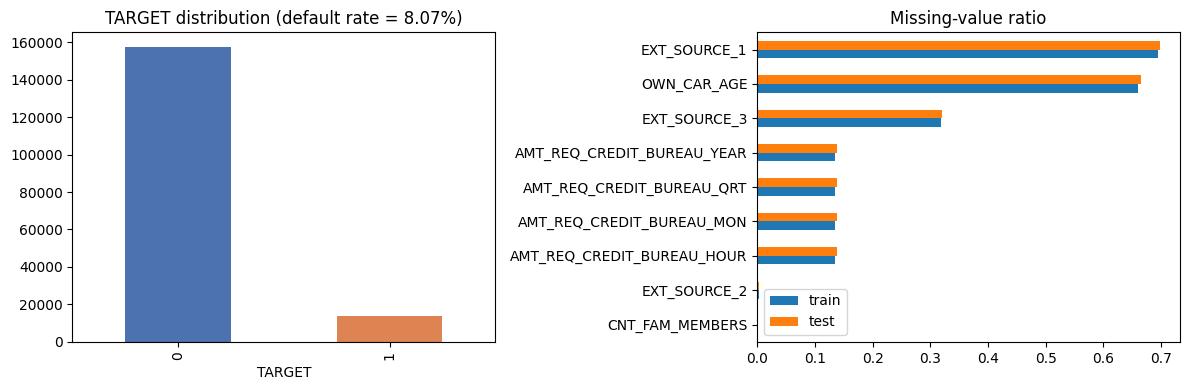

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train["TARGET"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"])
ax[0].set_title(f"TARGET distribution (default rate = {train.TARGET.mean():.2%})")
miss = pd.concat([train.drop(columns="TARGET").isna().mean(), test.isna().mean()], axis=1, keys=["train", "test"])
miss = miss[miss.train > 0].sort_values("train")
miss.plot.barh(ax=ax[1]); ax[1].set_title("Missing-value ratio")
plt.tight_layout(); plt.show()

**Findings:** the target is imbalanced (~8% defaults) → use AUC-friendly models and **stratified** folds. `EXT_SOURCE_1` and `OWN_CAR_AGE` are mostly missing; missingness is itself informative, so I let the tree models handle `NaN` natively instead of imputing.

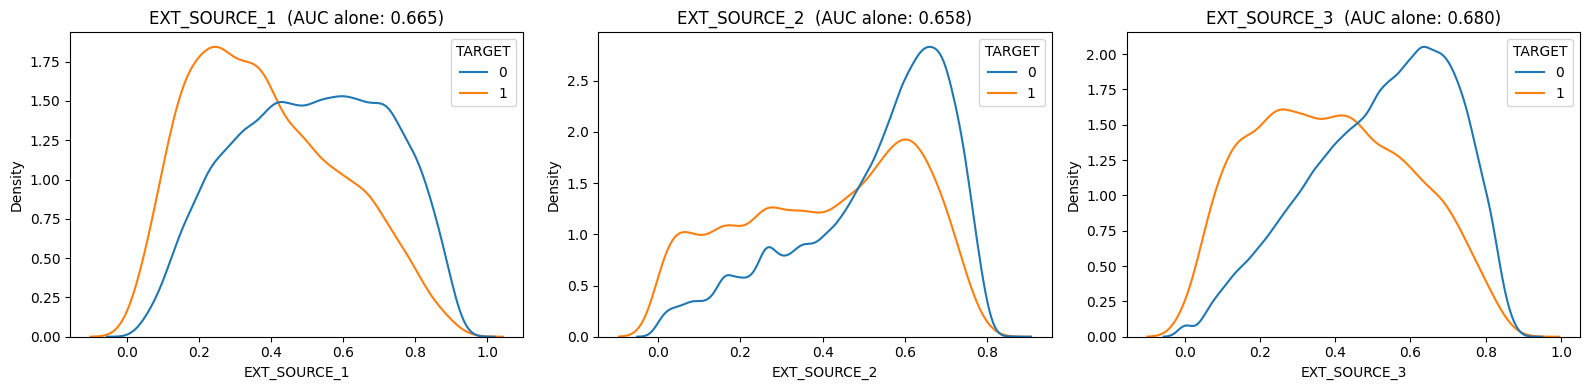

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=train, x=c, hue="TARGET", common_norm=False, ax=ax)
    ax.set_title(f"{c}  (AUC alone: {roc_auc_score(train.TARGET[train[c].notna()], -train[c].dropna()):.3f})")
plt.tight_layout(); plt.show()

**Findings:** the three external credit scores are by far the strongest single predictors (lower score → higher default risk). Combining them (mean, product, weighted sum, min/max) should help.

DAYS_EMPLOYED == 365243: 30898 rows; default rate 5.42% vs 8.66%


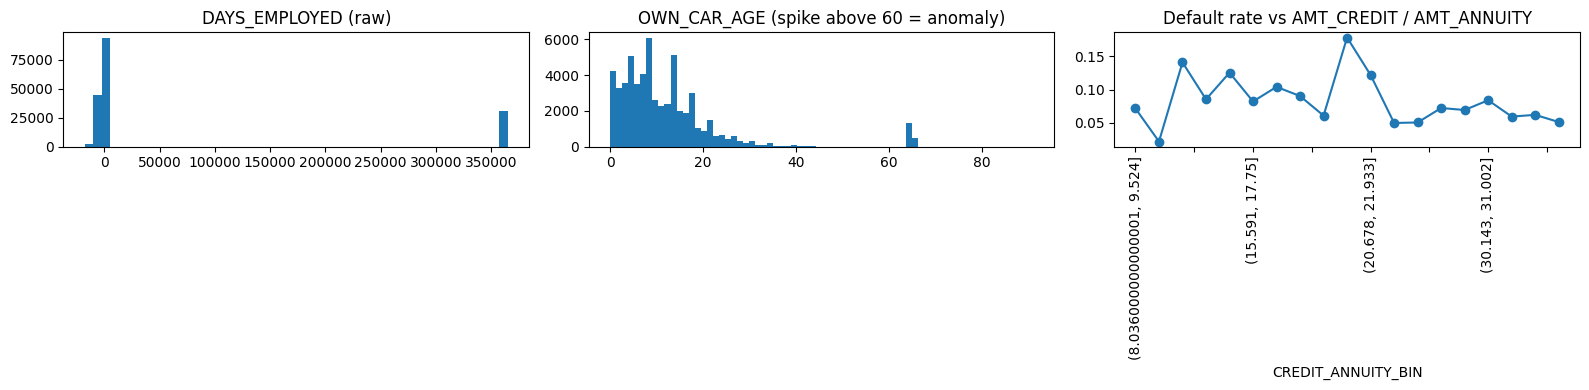

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(train.DAYS_EMPLOYED, bins=50); axes[0].set_title("DAYS_EMPLOYED (raw)")
print("DAYS_EMPLOYED == 365243:", (train.DAYS_EMPLOYED == 365243).sum(), "rows; default rate",
      f"{train.loc[train.DAYS_EMPLOYED == 365243, 'TARGET'].mean():.2%} vs {train.loc[train.DAYS_EMPLOYED != 365243, 'TARGET'].mean():.2%}")
axes[1].hist(train.OWN_CAR_AGE.dropna(), bins=70); axes[1].set_title("OWN_CAR_AGE (spike above 60 = anomaly)")
r = (train.AMT_CREDIT / train.AMT_ANNUITY)
train.assign(CREDIT_ANNUITY_BIN=pd.qcut(r, 20, duplicates="drop")).groupby("CREDIT_ANNUITY_BIN")["TARGET"].mean().plot(ax=axes[2], marker="o")
axes[2].set_title("Default rate vs AMT_CREDIT / AMT_ANNUITY"); axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

**Findings:**
* `DAYS_EMPLOYED = 365243` (≈1000 years) is a placeholder used for pensioners/unemployed → replace with `NaN` and add a flag.
* `OWN_CAR_AGE` has an unnatural spike at 60+ → treat as `NaN`.
* `AMT_CREDIT / AMT_ANNUITY` (≈ loan length in months) has a clear **non-monotonic** relation with default — a very strong engineered feature.

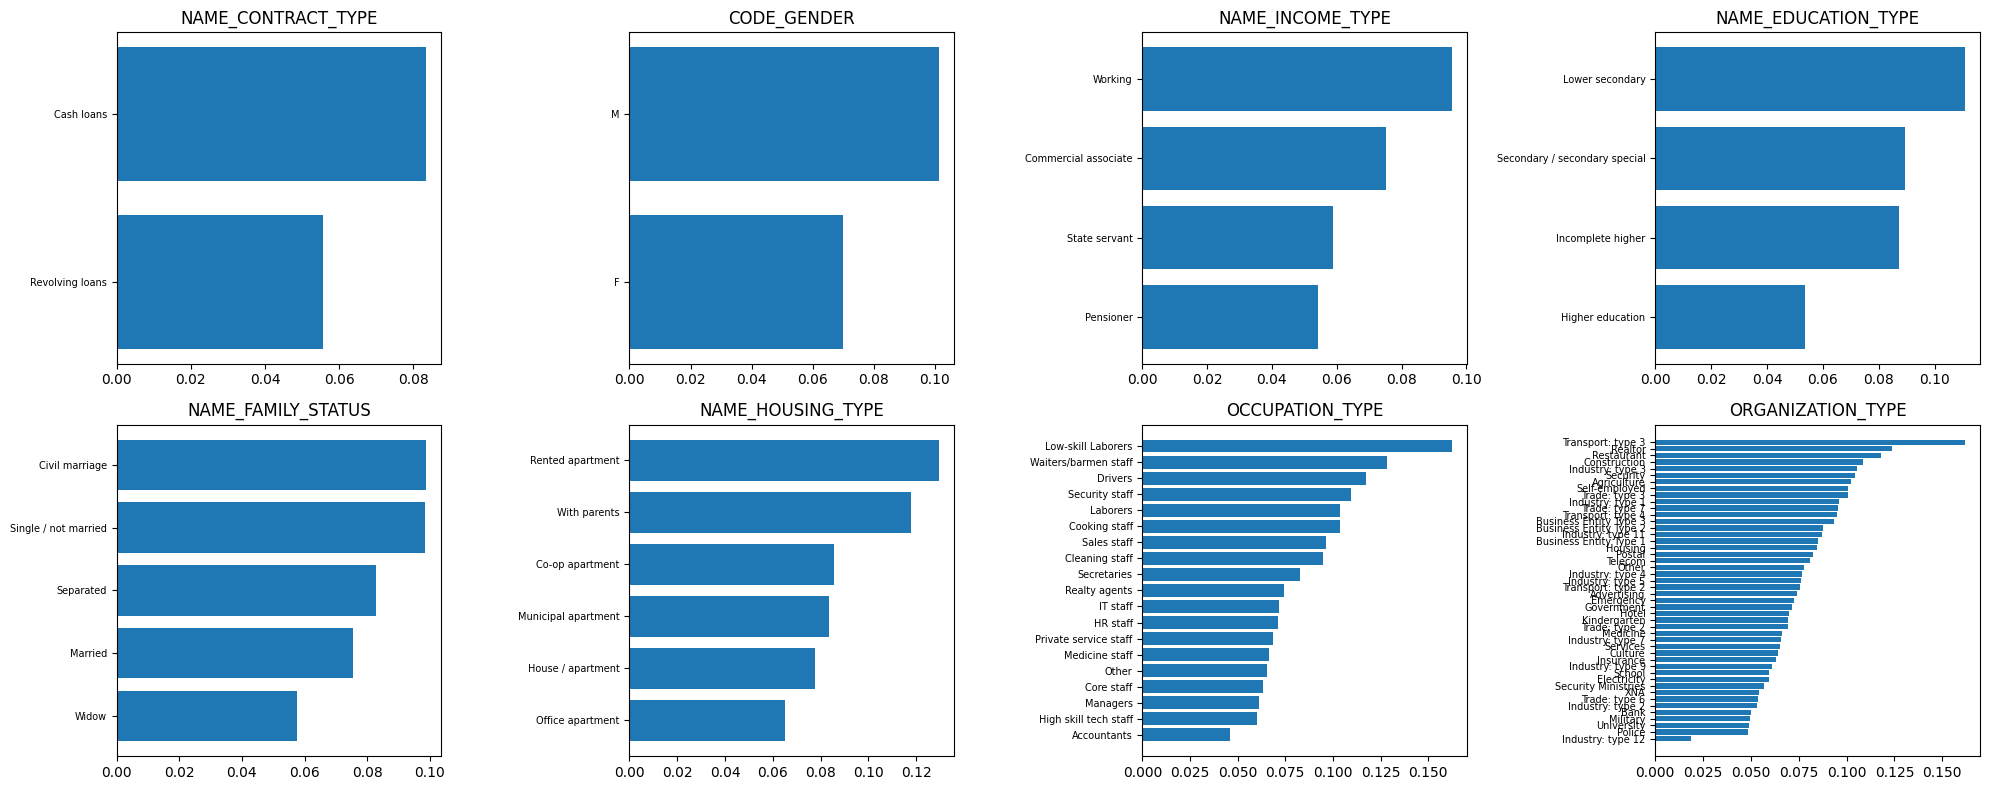

In [8]:
cat_cols = train.select_dtypes("object").columns.tolist()
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    s = train.groupby(c)["TARGET"].agg(["mean", "size"]).sort_values("mean")
    s = s[s["size"] > 200]
    ax.barh(s.index.astype(str), s["mean"]); ax.set_title(c); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

**Findings:** default rates differ strongly across occupation, organization, income type and education, so these categories are useful. Native categorical handling (LightGBM/CatBoost/XGBoost) and count encoding are used instead of large one-hot matrices.

## 4. Preprocessing & Feature Engineering
Train and test are processed together so that both get identical transformations. **The target is never used here** — group means and value counts are computed only from feature columns, so there is no target leakage.

**Key idea — implied interest rate.** The data has the loan amount (`AMT_CREDIT`) and the monthly payment (`AMT_ANNUITY`) but not the loan length or interest rate. Using the standard annuity formula $A = C\cdot\frac{r}{1-(1+r)^{-n}}$, I solve for the monthly rate $r$ for each common loan length $n$, and take the shortest length that gives a plausible rate (≥ 0.5 %/month) as the estimated term. The interest rate a lender charges reflects *the lender's own risk assessment* of the client, so it is highly predictive. In my CV experiments these features alone raised LightGBM AUC from 0.7601 to 0.7636.

| LightGBM experiment (5-fold CV AUC) | AUC |
|---|---|
| Base features | 0.76011 |
| + implied rates (8 terms) | 0.76302 |
| + KNN target-mean feature (500 neighbours) | 0.75886 (worse → not used) |
| + implied rates (11 terms) + term / total interest / relative rate | **0.76356** |

In [9]:
y = train["TARGET"].values
n_train = len(train)
df = pd.concat([train.drop(columns="TARGET"), test], ignore_index=True)
cat_cols = df.select_dtypes("object").columns.tolist()

TERMS = [6, 10, 12, 18, 24, 30, 36, 42, 48, 54, 60]   # common consumer-loan lengths (months)

def implied_monthly_rate(C, A, n):
    """Solve the annuity formula  A = C * r / (1 - (1 + r)^-n)  for the monthly rate r (vectorised bisection).
    Returns NaN when n payments of A cannot even repay the principal C."""
    lo, hi = np.full(len(C), 1e-7), np.full(len(C), 0.2)
    for _ in range(60):
        mid = (lo + hi) / 2
        too_high = C * mid / (1 - (1 + mid) ** (-n)) > A
        hi, lo = np.where(too_high, mid, hi), np.where(too_high, lo, mid)
    r = (lo + hi) / 2
    r[A * n <= C] = np.nan
    return r

def make_features(df):
    df = df.copy()
    # --- anomaly cleaning ---
    df["DAYS_EMPLOYED_ANOM"] = (df.DAYS_EMPLOYED == 365243).astype(int)
    df.loc[df.DAYS_EMPLOYED == 365243, "DAYS_EMPLOYED"] = np.nan
    df.loc[df.OWN_CAR_AGE >= 60, "OWN_CAR_AGE"] = np.nan
    df.loc[df.CODE_GENDER == "XNA", "CODE_GENDER"] = np.nan
    df.loc[df.ORGANIZATION_TYPE == "XNA", "ORGANIZATION_TYPE"] = np.nan
    df.loc[df.DAYS_LAST_PHONE_CHANGE == 0, "DAYS_LAST_PHONE_CHANGE"] = np.nan
    # --- financial ratios ---
    df["CREDIT_ANNUITY"] = df.AMT_CREDIT / df.AMT_ANNUITY          # ~ loan term in months
    df["CREDIT_GOODS"] = df.AMT_CREDIT / df.AMT_GOODS_PRICE        # credit above goods price (insurance, fees)
    df["CREDIT_GOODS_DIFF"] = df.AMT_CREDIT - df.AMT_GOODS_PRICE
    df["CREDIT_INCOME"] = df.AMT_CREDIT / df.AMT_INCOME_TOTAL
    df["ANNUITY_INCOME"] = df.AMT_ANNUITY / df.AMT_INCOME_TOTAL    # payment burden
    df["GOODS_INCOME"] = df.AMT_GOODS_PRICE / df.AMT_INCOME_TOTAL
    df["INCOME_PER_PERSON"] = df.AMT_INCOME_TOTAL / df.CNT_FAM_MEMBERS
    df["INCOME_PER_CHILD"] = df.AMT_INCOME_TOTAL / (1 + df.CNT_CHILDREN)
    df["ANNUITY_PER_PERSON"] = df.AMT_ANNUITY / df.CNT_FAM_MEMBERS
    # --- time features ---
    df["AGE_YEARS"] = -df.DAYS_BIRTH / 365.25
    df["EMPLOYED_BIRTH"] = df.DAYS_EMPLOYED / df.DAYS_BIRTH
    df["REG_BIRTH"] = df.DAYS_REGISTRATION / df.DAYS_BIRTH
    df["ID_BIRTH"] = df.DAYS_ID_PUBLISH / df.DAYS_BIRTH
    df["PHONE_BIRTH"] = df.DAYS_LAST_PHONE_CHANGE / df.DAYS_BIRTH
    df["PHONE_EMPLOYED"] = df.DAYS_LAST_PHONE_CHANGE / df.DAYS_EMPLOYED
    df["CAR_BIRTH"] = df.OWN_CAR_AGE / df.AGE_YEARS
    df["AGE_AT_END"] = df.AGE_YEARS + df.CREDIT_ANNUITY / 12        # age when the loan ends
    df["ID_MINUS_REG"] = df.DAYS_ID_PUBLISH - df.DAYS_REGISTRATION
    # --- external score aggregates ---
    ext = df[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
    df["EXT_MEAN"] = ext.mean(axis=1); df["EXT_STD"] = ext.std(axis=1)
    df["EXT_MIN"] = ext.min(axis=1); df["EXT_MAX"] = ext.max(axis=1)
    df["EXT_PROD"] = ext.prod(axis=1, min_count=3)
    df["EXT_NAN"] = ext.isna().sum(axis=1)
    df["EXT_W"] = (2 * df.EXT_SOURCE_1.fillna(df.EXT_MEAN) + df.EXT_SOURCE_2.fillna(df.EXT_MEAN)
                   + 3 * df.EXT_SOURCE_3.fillna(df.EXT_MEAN))
    df["EXT_2x3"] = df.EXT_SOURCE_2 * df.EXT_SOURCE_3
    df["EXT_1x2"] = df.EXT_SOURCE_1 * df.EXT_SOURCE_2
    df["EXT_1x3"] = df.EXT_SOURCE_1 * df.EXT_SOURCE_3
    df["EXT_MEAN_CREDIT"] = df.EXT_MEAN * df.CREDIT_ANNUITY
    df["EXT_MEAN_AGE"] = df.EXT_MEAN / df.AGE_YEARS
    df["BUREAU_SUM"] = df[[c for c in df.columns if c.startswith("AMT_REQ")]].sum(axis=1, min_count=1)
    df["N_MISSING"] = df.isna().sum(axis=1)
    # --- group-relative features: how does an applicant compare with similar people? ---
    for g in ["ORGANIZATION_TYPE", "OCCUPATION_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]:
        for c in ["AMT_INCOME_TOTAL", "EXT_MEAN", "CREDIT_ANNUITY", "AMT_ANNUITY", "AGE_YEARS"]:
            df[f"{c}_DIV_{g}"] = df[c] / df.groupby(g)[c].transform("mean")
    key = df.NAME_EDUCATION_TYPE.astype(str) + "_" + df.CODE_GENDER.astype(str) + "_" + df.OCCUPATION_TYPE.astype(str)
    for c in ["AMT_INCOME_TOTAL", "EXT_MEAN", "AMT_CREDIT"]:
        df[f"{c}_DIFF_GRP"] = df[c] - df.groupby(key)[c].transform("median")
    # --- implied interest rate (see explanation above) ---
    C_, A_ = df.AMT_CREDIT.values, df.AMT_ANNUITY.values
    R = np.vstack([implied_monthly_rate(C_, A_, n) for n in TERMS]).T
    for j, n in enumerate(TERMS):
        df[f"RATE_{n}"] = R[:, j]
    T = np.array(TERMS)
    term = np.where(np.nan_to_num(R, nan=-1) >= 0.005, T, 999).min(axis=1).astype(float)
    term[term == 999] = np.nan
    df["TERM_GUESS"] = term                                  # shortest plausible loan term
    col = {t: j for j, t in enumerate(TERMS)}
    df["RATE_GUESS"] = [R[i, col[int(t)]] if t == t else np.nan for i, t in enumerate(term)]
    df["TOTAL_INTEREST"] = A_ * df.TERM_GUESS - C_
    df["INTEREST_INCOME"] = df.TOTAL_INTEREST / df.AMT_INCOME_TOTAL
    df["RATE_DIV_CONTRACT"] = df.RATE_GUESS / df.groupby(["NAME_CONTRACT_TYPE", "TERM_GUESS"])["RATE_GUESS"].transform("mean")
    df["RATE_x_EXT"] = df.RATE_GUESS * df.EXT_MEAN
    # --- count encodings ---
    for c in cat_cols:
        df[c + "_CNT"] = df[c].map(df[c].value_counts())
    df["CREDIT_CNT"] = df.AMT_CREDIT.map(df.AMT_CREDIT.value_counts())
    df["ANNUITY_CNT"] = df.AMT_ANNUITY.map(df.AMT_ANNUITY.value_counts())
    for c in cat_cols:
        df[c] = df[c].astype("category")
    return df

X_base = make_features(df).drop(columns=["SK_ID_CURR", "FLAG_MOBIL"])   # FLAG_MOBIL is constant
print("number of base features:", X_base.shape[1])

number of base features: 114


### 4.2 Round-2 features
After my first submission (public AUC 0.76891), I ran a second round of experiments. Each new feature group was tested on LightGBM 5-fold CV against the 114 base features (0.76376):

| Feature group | Idea | CV AUC alone |
|---|---|---|
| **Model-based EXT_SOURCE imputation** | Predict each external score from the other (non-EXT) columns with a LightGBM regressor (out-of-fold on the known rows, **no target used**). Add the prediction, the filled-in score, and the residual (actual − expected) | **0.76575 (+0.0020)** |
| Amount patterns | Popularity of the pricing tier and of the exact (credit, annuity) pair, round-number flags | 0.76392 |
| ID-document & date features | Age when the ID was issued, ID overdue for renewal at age 20 / 45, age at job start | 0.76388 |
| Rate relative to peers | Rate ÷ median rate of applicants with a similar EXT score and term | 0.76346 |
| *All four together* | | **0.76649 (+0.0027)** |

Tried and **rejected**: a "most popular rate tier" term estimate (0.76572) and a heavier cross-EXT imputation model (0.76581, no gain for 3× the cost).

The imputation residual captures *"this applicant's external score is lower than their profile would suggest"*, which a tree model cannot easily build from raw columns.

In [10]:
from sklearn.model_selection import KFold

def add_amount_features(X):
    X = X.copy()
    r = (X.RATE_GUESS * 1200).round(2)                                  # annual rate in %, 2 decimals
    X["RATE_ROUND_CNT"] = r.map(r.value_counts())                       # popularity of the pricing tier
    pair = df.AMT_CREDIT.astype(str) + "_" + df.AMT_ANNUITY.astype(str)
    X["CREDIT_ANNUITY_PAIR_CNT"] = pair.map(pair.value_counts()).values
    X["GOODS_CNT"] = df.AMT_GOODS_PRICE.map(df.AMT_GOODS_PRICE.value_counts()).values
    X["CREDIT_ROUND_1000"] = (df.AMT_CREDIT % 1000 == 0).astype(int).values
    X["GOODS_ROUND_10000"] = (df.AMT_GOODS_PRICE % 10000 == 0).astype(int).values
    X["ANNUITY_DECIMALS"] = (df.AMT_ANNUITY * 100 % 100).values
    X["CREDIT_ANNUITY_FRAC"] = X.CREDIT_ANNUITY - np.floor(X.CREDIT_ANNUITY)
    return X

def add_date_features(X):
    X = X.copy()
    age = -df.DAYS_BIRTH / 365.25
    id_age = (df.DAYS_ID_PUBLISH - df.DAYS_BIRTH) / 365.25             # age when the ID document was issued
    X["AGE_AT_ID"] = id_age.values
    X["ID_OVERDUE_20"] = ((age >= 20.2) & (id_age < 20)).astype(int).values
    X["ID_OVERDUE_45"] = ((age >= 45.2) & (id_age < 45)).astype(int).values
    X["ID_RENEW_GAP"] = np.where(age >= 45, id_age - 45, np.where(age >= 20, id_age - 20, id_age - 14))
    emp = df.DAYS_EMPLOYED.where(df.DAYS_EMPLOYED != 365243)
    X["AGE_AT_JOB_START"] = ((emp - df.DAYS_BIRTH) / 365.25).values
    X["AGE_AT_REGISTRATION"] = ((df.DAYS_REGISTRATION - df.DAYS_BIRTH) / 365.25).values
    X["PHONE_MINUS_ID"] = (df.DAYS_LAST_PHONE_CHANGE - df.DAYS_ID_PUBLISH).values
    X["PHONE_MINUS_EMP"] = (df.DAYS_LAST_PHONE_CHANGE - emp).values
    return X

def add_peer_rate_features(X):
    X = X.copy()
    ext_bin = pd.qcut(X.EXT_MEAN, 20, labels=False, duplicates="drop")
    X["RATE_DIV_EXTBIN"] = X.RATE_GUESS / X.groupby([ext_bin, X.TERM_GUESS])["RATE_GUESS"].transform("median")
    X["RATE_DIV_INCOME_TYPE"] = X.RATE_GUESS / X.groupby(df.NAME_INCOME_TYPE.values)["RATE_GUESS"].transform("median")
    X["CREDIT_DIV_TERM_MEDIAN"] = X.AMT_CREDIT / X.groupby("TERM_GUESS")["AMT_CREDIT"].transform("median")
    return X

def add_ext_imputation(X, base):
    """Model-based imputation of EXT_SOURCE_1/2/3 from the non-EXT base features (TARGET is never used).
    Known rows get out-of-fold predictions; missing rows get the average of the 5 fold models."""
    X = X.copy()
    feats = [c for c in base.columns if "EXT" not in c and "RATE_x" not in c]
    for e in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
        known = np.where(base[e].notna().values)[0]; unknown = np.where(base[e].isna().values)[0]
        pred = np.zeros(len(base))
        for a, b in KFold(5, shuffle=True, random_state=SEED).split(known):
            m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=64, colsample_bytree=0.7,
                                  random_state=SEED, n_jobs=N_JOBS, verbose=-1)
            m.fit(base.iloc[known[a]][feats], base[e].values[known[a]])
            pred[known[b]] = m.predict(base.iloc[known[b]][feats])
            pred[unknown] += m.predict(base.iloc[unknown][feats]) / 5
        X[e + "_PRED"] = pred
        X[e + "_FILLED"] = base[e].fillna(pd.Series(pred, index=base.index))
        X[e + "_RESID"] = base[e] - pred
    X["EXT_FILLED_MEAN"] = X[["EXT_SOURCE_1_FILLED", "EXT_SOURCE_2_FILLED", "EXT_SOURCE_3_FILLED"]].mean(axis=1)
    X["EXT_FILLED_W"] = 2 * X.EXT_SOURCE_1_FILLED + X.EXT_SOURCE_2_FILLED + 3 * X.EXT_SOURCE_3_FILLED
    return X

t0 = time.time()
X_all = add_ext_imputation(add_peer_rate_features(add_date_features(add_amount_features(X_base))), X_base)
X_train, X_test = X_all.iloc[:n_train].reset_index(drop=True), X_all.iloc[n_train:].reset_index(drop=True)
print(f"number of features: {X_train.shape[1]}  ({time.time() - t0:.0f}s)")

number of features: 143  (329s)


## 5. Model Training with Stratified 5-Fold Cross-Validation
Each model is trained 5 times; each time one fold is held out for early stopping/validation. This gives
* an **out-of-fold (OOF)** prediction for every training row → honest CV AUC and data to choose blend weights, and
* 5 test predictions that are averaged → more stable test predictions.

In [11]:
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train, y))
results = {}

def run_cv(name, fit_predict):
    t0 = time.time()
    oof, pred = np.zeros(n_train), np.zeros(len(X_test))
    for k, (tr, va) in enumerate(folds):
        oof[va], p = fit_predict(tr, va)
        pred += p / N_FOLDS
        print(f"  [{name}] fold {k}: AUC = {roc_auc_score(y[va], oof[va]):.5f}")
    results[name] = (oof, pred)
    print(f"{name}: OOF AUC = {roc_auc_score(y, oof):.5f}  ({time.time() - t0:.0f}s)")

### 5.1 LightGBM

In [12]:
lgb_params = dict(objective="binary", learning_rate=0.02, num_leaves=32, min_child_samples=80,
                  subsample=0.85, subsample_freq=1, colsample_bytree=0.5, reg_alpha=0.1, reg_lambda=5,
                  cat_smooth=30, min_data_per_group=100, n_estimators=10000,
                  random_state=SEED, n_jobs=N_JOBS, verbose=-1)
lgb_importance = pd.Series(0.0, index=X_train.columns)

def fit_lgb(tr, va):
    m = lgb.LGBMClassifier(**lgb_params)
    m.fit(X_train.iloc[tr], y[tr], eval_set=[(X_train.iloc[va], y[va])], eval_metric="auc",
          callbacks=[lgb.early_stopping(200, verbose=False)])
    lgb_importance[:] += m.booster_.feature_importance("gain") / N_FOLDS
    return m.predict_proba(X_train.iloc[va])[:, 1], m.predict_proba(X_test)[:, 1]

run_cv("LightGBM", fit_lgb)

  [LightGBM] fold 0: AUC = 0.76304


  [LightGBM] fold 1: AUC = 0.76557


  [LightGBM] fold 2: AUC = 0.77212


  [LightGBM] fold 3: AUC = 0.76420


  [LightGBM] fold 4: AUC = 0.76768
LightGBM: OOF AUC = 0.76649  (263s)


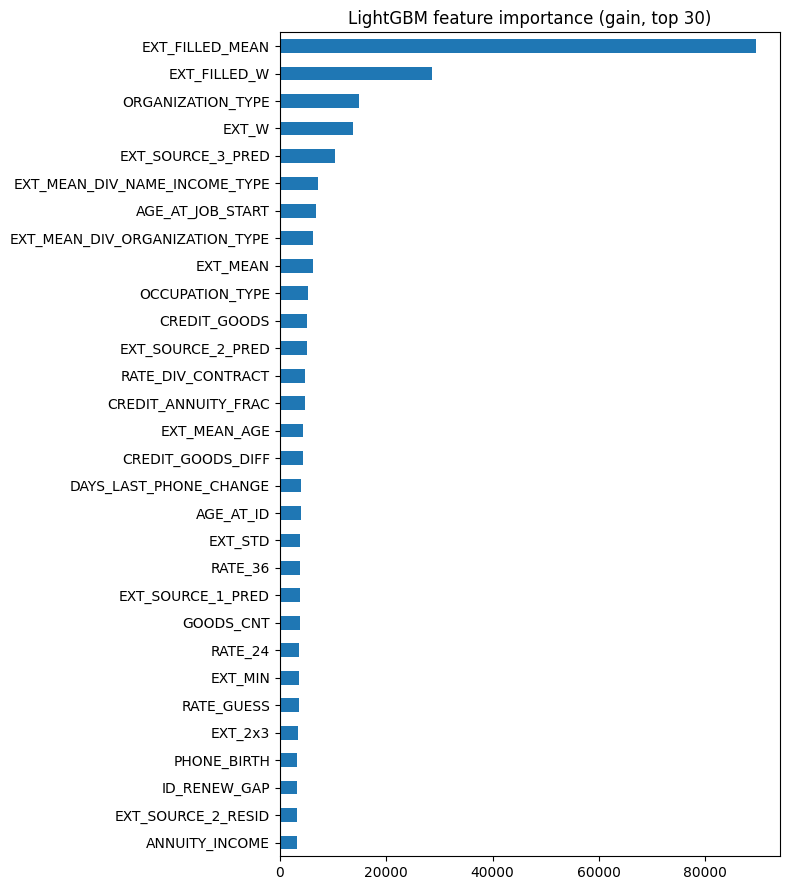

In [13]:
plt.figure(figsize=(8, 9))
lgb_importance.sort_values().tail(30).plot.barh()
plt.title("LightGBM feature importance (gain, top 30)"); plt.tight_layout(); plt.show()

### 5.2 CatBoost (ordered target statistics for categorical features)

In [14]:
X_train_cb, X_test_cb = X_train.copy(), X_test.copy()
for c in cat_cols:
    X_train_cb[c] = X_train_cb[c].astype(str); X_test_cb[c] = X_test_cb[c].astype(str)

def fit_cb(tr, va):
    # max_ctr_complexity=1 disables categorical feature combinations -> ~10x faster with similar accuracy
    m = CatBoostClassifier(iterations=5000, learning_rate=0.06, depth=6, l2_leaf_reg=5, eval_metric="AUC",
                           max_ctr_complexity=1, border_count=128,
                           random_seed=SEED, od_type="Iter", od_wait=200, verbose=0,
                           thread_count=N_JOBS, cat_features=cat_cols)
    m.fit(X_train_cb.iloc[tr], y[tr], eval_set=(X_train_cb.iloc[va], y[va]), use_best_model=True)
    return m.predict_proba(X_train_cb.iloc[va])[:, 1], m.predict_proba(X_test_cb)[:, 1]

run_cv("CatBoost", fit_cb)

  [CatBoost] fold 0: AUC = 0.76409


  [CatBoost] fold 1: AUC = 0.76466


  [CatBoost] fold 2: AUC = 0.76860


  [CatBoost] fold 3: AUC = 0.76251


  [CatBoost] fold 4: AUC = 0.76638
CatBoost: OOF AUC = 0.76521  (998s)


### 5.3 XGBoost

In [15]:
def fit_xgb(tr, va):
    m = xgb.XGBClassifier(n_estimators=10000, learning_rate=0.02, max_depth=5, min_child_weight=10,
                          subsample=0.85, colsample_bytree=0.5, reg_lambda=5, tree_method="hist",
                          enable_categorical=True, max_cat_to_onehot=1, eval_metric="auc",
                          early_stopping_rounds=200, random_state=SEED, n_jobs=N_JOBS)
    m.fit(X_train.iloc[tr], y[tr], eval_set=[(X_train.iloc[va], y[va])], verbose=False)
    return m.predict_proba(X_train.iloc[va])[:, 1], m.predict_proba(X_test)[:, 1]

run_cv("XGBoost", fit_xgb)

  [XGBoost] fold 0: AUC = 0.76225


  [XGBoost] fold 1: AUC = 0.76567


  [XGBoost] fold 2: AUC = 0.77029


  [XGBoost] fold 3: AUC = 0.76375


  [XGBoost] fold 4: AUC = 0.76636
XGBoost: OOF AUC = 0.76562  (1222s)


## 6. Ensemble (rank averaging)
AUC depends only on the **order** of predictions, so each model's predictions are converted to ranks (0–1) before averaging. Blend weights are chosen by a grid search on the OOF predictions (never on the test set).

In [16]:
names = list(results)
rank = lambda p: rankdata(p) / len(p)
oof_r = {n: rank(results[n][0]) for n in names}
test_r = {n: rank(results[n][1]) for n in names}

best_auc, best_w = 0, None
grid = np.round(np.arange(0, 1.0001, 0.05), 2)
for w0 in grid:
    for w1 in grid:
        if w0 + w1 > 1: continue
        w = (w0, w1, round(1 - w0 - w1, 2))
        auc = roc_auc_score(y, sum(wi * oof_r[n] for wi, n in zip(w, names)))
        if auc > best_auc: best_auc, best_w = auc, w

summary = pd.DataFrame({"OOF AUC": [roc_auc_score(y, results[n][0]) for n in names]}, index=names)
summary.loc["Equal-weight rank blend"] = roc_auc_score(y, sum(oof_r[n] for n in names) / 3)
summary.loc[f"Weighted rank blend {dict(zip(names, best_w))}"] = best_auc
display(summary.round(5))

oof_blend = sum(w * oof_r[n] for w, n in zip(best_w, names))
pred = sum(w * test_r[n] for w, n in zip(best_w, names))
print("Correlation between model test predictions:")
display(pd.DataFrame(test_r).corr().round(3))

,OOF AUC
LightGBM,0.76649
CatBoost,0.76521
XGBoost,0.76562
Equal-weight rank blend,0.76758
"Weighted rank blend {'LightGBM': 0.45, 'CatBoost': 0.4, 'XGBoost': 0.15}",0.76764


Correlation between model test predictions:


,LightGBM,CatBoost,XGBoost
LightGBM,1.000,0.984,0.996
CatBoost,0.984,1.000,0.982
XGBoost,0.996,0.982,1.000


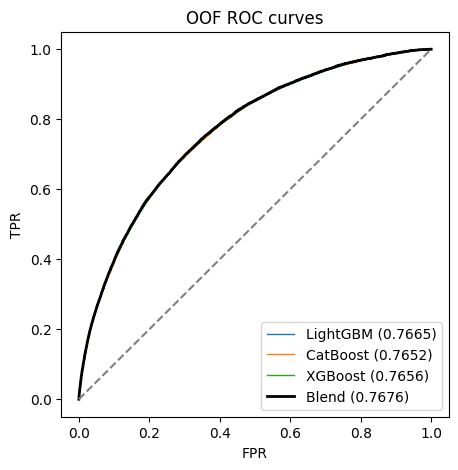

In [17]:
plt.figure(figsize=(5, 5))
for n in names:
    fpr, tpr, _ = roc_curve(y, results[n][0]); plt.plot(fpr, tpr, lw=1, label=f"{n} ({roc_auc_score(y, results[n][0]):.4f})")
fpr, tpr, _ = roc_curve(y, oof_blend); plt.plot(fpr, tpr, lw=2, c="k", label=f"Blend ({best_auc:.4f})")
plt.plot([0, 1], [0, 1], "--", c="grey"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("OOF ROC curves"); plt.legend(); plt.show()

## 7. Creating Prediction Results

### 7.1 Saving the prediction as CSV file [DO NOT CHANGE]

In [18]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.357990
1,171203,0.945276
2,171204,0.892167
3,171205,0.754551
4,171206,0.923872
...,...,...
61495,232697,0.903639
61496,232698,0.157973
61497,232699,0.429151
61498,232700,0.935615


In [19]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

In [20]:
# Sanity checks on the submission format
chk = pd.read_csv(output_file)
assert list(chk.columns) == ["SK_ID_CURR", "TARGET"] and len(chk) == len(test)
assert (chk.SK_ID_CURR.values == test.SK_ID_CURR.values).all() and chk.TARGET.between(0, 1).all() and chk.TARGET.notna().all()
print("submission.csv OK:", chk.shape)

submission.csv OK: (61500, 2)


### 7.2 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
Save the notebook (Ctrl+S / Cmd+S) before running this cell.

In [21]:
import zipfile

notebook_filename = "solution.ipynb"  # name of this notebook
zip_filename = "solution.zip"
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")

Successfully created: D:\Competition\solution.zip


## 8. Conclusions & possible improvements
* The engineered **credit/annuity ratio** and **EXT_SOURCE aggregates** are the most important features; group-relative features (e.g. an applicant's EXT score relative to their organization type) add further signal.
* Three different gradient-boosting libraries make partly uncorrelated errors, so the rank-average ensemble beats every single model in CV.
* 5-fold CV AUC is very stable across folds, so the public-leaderboard score (computed on a subset of test) should be close to the CV score; I select the final submission by CV, not by the public leaderboard, to avoid overfitting it.
* Further ideas: hyperparameter search with Optuna, more seeds per model, and a neural network for ensemble diversity.